# Ground station census

Given a rectangular bounding box and an analysis period, this notebook queries the OpenAQ
database for stations in that region which measure PM2.5, and checks how many are still
actively reporting *and* have been reporting for long enough to cover the analysis period.

The activity check is a bulk join plus a metadata check, neither requiring a per-station API
call:

1. Pull the network-wide `latest` feed for PM2.5 once (paginated) — one reading per sensor,
   for every PM2.5 sensor OpenAQ knows about.
2. Pull the candidate station list for the bounding box of interest.
3. For each candidate station, look up its PM2.5 sensor's most recent reading in the latest
   feed, and keep the station if that reading is within `MAX_AGE_DAYS` (recency).
4. Also require the sensor to have started reporting on or before the analysis period's start
   date (`DAY_START`). A sensor that's currently active but only came online a few months ago
   can never have full coverage over the whole period, no matter how recent its last reading
   is — this is free to check since `datetime_first` is already on the station objects from
   step 2, no extra API call needed. Note this only rules out sensors that started too late; it
   can't catch gaps *within* the period (e.g. six months offline in the middle) — that needs to
   be checked against the actual pulled measurements in the next notebook.

This is a quick sanity check on the candidate region *before* building the rest of the pipeline. If the region
doesn't have enough well-distributed, sufficiently-long-reporting active stations, the fallback regions are
Sub-Saharan Africa's OpenAQ-reporting countries or a Latin America cluster (Mexico, Colombia, Peru, Brazil).

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [3]:
from pathlib import Path

import dotenv
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import yaml
from openaq import OpenAQ

import monitoring_deserts.data.fetch_openaq as census

## Configuration

Candidate region: South Asia (India, Pakistan, Bangladesh, Nepal, Sri Lanka) plus Afghanistan,
per the plan's Section 3 recommendation. Study period: the two most recent full calendar years
relative to today, per Section 8 Phase A step 3.

In [5]:
# Bounding box: (min lon, min lat, max lon, max lat) -- South Asia + Afghanistan
BOUNDING_BOX = (60.424805, 5.353521, 93.383789, 38.272689)

# Half-open analysis period
PERIOD = DAY_START, DAY_END = ("2024-01-01", "2026-01-01")

# A station's PM2.5 sensor must have reported within this many days of today
# to be considered active.
MAX_AGE_DAYS = 150

# Rough viability bar: below this, fall back to
# one of the alternate regions rather than building the rest of
# the pipeline on a too-sparse network.
MIN_ACTIVE_STATIONS = 40

OUTPUT_DIR = Path("../data/raw/station_census")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dotenv.load_dotenv()
client = OpenAQ()

## Step 1 — PM2.5 parameter ID

Don't hardcode this; OpenAQ assigns it, so confirm it directly.

In [6]:
pm25_id = census.get_pollutant_id(client, poll_name="PM25")
print(f"PM2.5 parameter ID: {pm25_id}")

PM2.5 parameter ID: 2


## Step 2 — Candidate stations in the bounding box

All stations in `BOUNDING_BOX` that have at least one PM2.5 sensor, regardless of whether
that sensor is still active.

In [7]:
stations_df, stations_list = census.pull_stations(client, BOUNDING_BOX, pollutant_id=pm25_id)
print(f"Candidate PM2.5 stations in the bounding box: {len(stations_df)}")
stations_df[["id", "name", "country.code", "country.name", "coordinates.latitude", "coordinates.longitude"]].head()

Candidate PM2.5 stations in the bounding box: 1350


,id,name,country.code,country.name,coordinates.latitude,coordinates.longitude
0,12,SPARTAN - IIT Kanpur,IN,India,26.519000,80.233000
1,13,"Delhi Technological University, Delhi - CPCB",IN,India,28.744000,77.120000
2,15,IGI Airport,IN,India,28.560000,77.094000
3,16,Civil Lines,IN,India,28.678700,77.226200
4,17,"R K Puram, Delhi - DPCC",IN,India,28.563262,77.186937


## Step 3 — Bulk activity check

Pull the network-wide `latest` feed for PM2.5 once (paginated) and join it against the
candidate stations on sensor ID, instead of calling `sensors.get()` once per candidate
station — the latter is what made the original version of this notebook time out after a few
hundred sequential requests.

`flag_active_stations` also takes `date_from=DAY_START`, so `is_active` requires both recency
*and* the sensor having started reporting on or before the analysis period begins — see the
intro cell for why.

In [9]:
latest_df = census.get_latest_by_parameter(client, pm25_id)
print(f"Sensors with a recent PM2.5 reading, network-wide: {len(latest_df)}")
latest_df.head()

Sensors with a recent PM2.5 reading, network-wide: 20931


,sensor_id,location_id,latitude,longitude,value,datetime_utc,datetime_local
0,8539597,2622686,35.218150,128.574250,22.0,2026-09-15T08:00:00Z,2026-09-15T17:00:00+09:00
1,23735,8152,54.883614,23.835835,-1.0,2026-09-15T07:00:00Z,2026-09-15T10:00:00+03:00
2,238048,43487,40.146500,117.070900,16.0,2021-08-09T11:00:00Z,2021-08-09T19:00:00+08:00
3,7320157,1772963,37.645530,-118.966760,9.0,2025-08-09T14:00:00Z,2025-08-09T07:00:00-07:00
4,6236505,1066093,38.592460,-82.806770,3.7,2026-09-15T08:00:00Z,2026-09-15T04:00:00-04:00


In [ ]:
stations_df = census.flag_active_stations(
    stations_df,
    stations_list,
    pm25_id,
    latest_df,
    max_age_days=MAX_AGE_DAYS,
    date_from=DAY_START,
)

n_candidate = len(stations_df)
n_recent = int(
    (
        stations_df["days_since_last"].notna()
        & stations_df["days_since_last"].le(MAX_AGE_DAYS)
    ).sum()
)
n_covers_window = int(stations_df["covers_window_start"].sum())
n_active = int(stations_df["is_active"].sum())

print(f"Candidate stations: {n_candidate}")
print(f"Reported within {MAX_AGE_DAYS} days (recency only): {n_recent}")
print(f"Sensor started on/before {DAY_START} (coverage-start only): {n_covers_window}")
print(f"Active (recency AND coverage-start): {n_active}")

## Step 4 — Active station counts by country

In [16]:
country_counts = (
    stations_df.loc[stations_df["is_active"], "country.name"]
    .value_counts()
    .rename("n_active_stations")
    .to_frame()
)
country_counts

,n_active_stations
country.name,
India,445
Pakistan,371
Nepal,80
Bangladesh,16
Bhutan,15
China,2
Sri Lanka,1


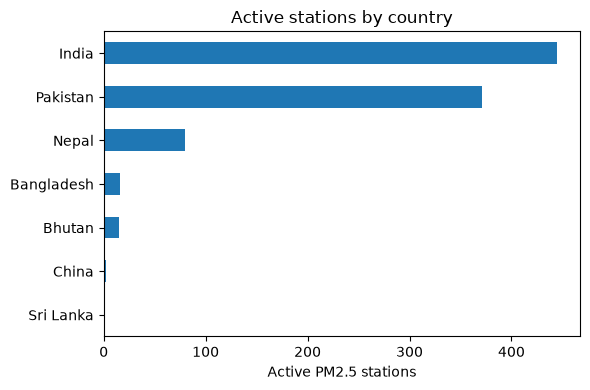

In [17]:
ax = country_counts["n_active_stations"].sort_values().plot.barh(figsize=(6, 4))
ax.set_xlabel("Active PM2.5 stations")
ax.set_ylabel("")
ax.set_title("Active stations by country")
plt.tight_layout()
plt.show()

## Step 5 — Map the stations

A quick visual check that active stations aren't all clustered in two or three cities, which
would starve later spatial cross-validation of independent test regions.

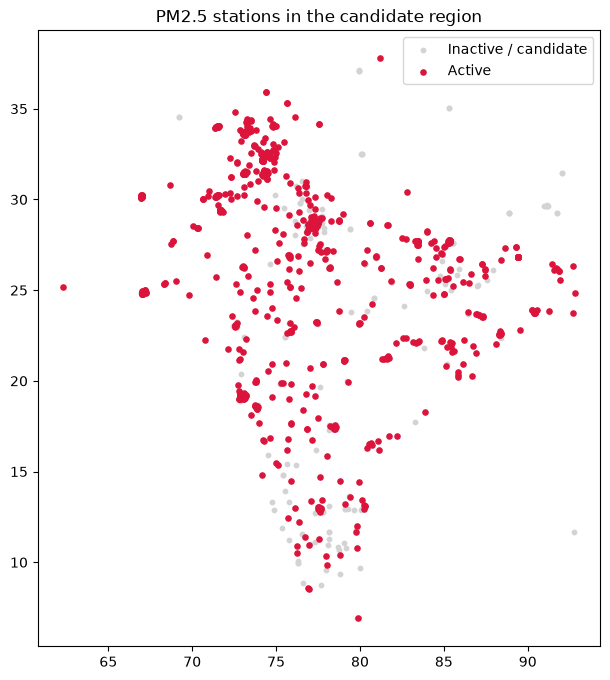

In [18]:
stations_gdf = gpd.GeoDataFrame(
    stations_df,
    geometry=gpd.points_from_xy(
        stations_df["coordinates.longitude"], stations_df["coordinates.latitude"]
    ),
    crs="EPSG:4326",
)

fig, ax = plt.subplots(figsize=(8, 8))
stations_gdf[~stations_gdf["is_active"]].plot(
    ax=ax, color="lightgray", markersize=10, label="Inactive / candidate"
)
stations_gdf[stations_gdf["is_active"]].plot(
    ax=ax, color="crimson", markersize=14, label="Active"
)
ax.set_title("PM2.5 stations in the candidate region")
ax.legend()
plt.show()

In [20]:
center_lat = stations_gdf["coordinates.latitude"].mean()
center_lon = stations_gdf["coordinates.longitude"].mean()
station_map = folium.Map(location=[center_lat, center_lon], zoom_start=5, tiles="cartodbpositron")

for _, row in stations_gdf.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4 if row["is_active"] else 2,
        color="crimson" if row["is_active"] else "lightgray",
        fill=True,
        fill_opacity=0.8,
        tooltip=f'{row["name"]} ({row["country.name"]})',
    ).add_to(station_map)

map_path = "../outputs/maps/stations_map.html"
station_map.save(str(map_path))
print(f"Saved interactive map to {map_path}")
station_map

Saved interactive map to ../outputs/station_census/stations_map.html


## Step 6 — Is this region viable?

Compares the active station count against the rough bar set in `MIN_ACTIVE_STATIONS`. This is
a sanity check, not a final verdict — also look at the map above for geographic clustering,
which a station count alone won't reveal.

In [22]:
if n_active >= MIN_ACTIVE_STATIONS:
    print(
        f"{n_active} active stations >= {MIN_ACTIVE_STATIONS}: "
        "the candidate region looks viable on station count alone."
    )
else:
    print(
        f"Only {n_active} active stations (< {MIN_ACTIVE_STATIONS}). "
        "Consider the fallback regions: Sub-Saharan Africa's "
        "OpenAQ-reporting countries, or a Latin America cluster (Mexico, Colombia, Peru, Brazil)."
    )

930 active stations >= 40: the candidate region looks viable on station count alone.


## Step 7 — Freeze the study scope and save outputs

Persist the bounding box, period, and station tables so later phases  build
on this exact decision rather than re-deriving it.

In [ ]:
scope = {
    "bounding_box": {
        "min_lon": BOUNDING_BOX[0],
        "min_lat": BOUNDING_BOX[1],
        "max_lon": BOUNDING_BOX[2],
        "max_lat": BOUNDING_BOX[3],
    },
    "period": {"start": DAY_START, "end": DAY_END},
    "pm25_parameter_id": pm25_id,
    "max_age_days": MAX_AGE_DAYS,
    "n_candidate_stations": n_candidate,
    "n_recent_stations": n_recent,
    "n_covers_window_start_stations": n_covers_window,
    "n_active_stations": n_active,
}

with open(OUTPUT_DIR / "census_scope.yaml", "w") as f:
    yaml.safe_dump(scope, f, sort_keys=False)

stations_df.to_csv(OUTPUT_DIR / "stations_candidate.csv", index=False)
stations_df[stations_df["is_active"]].to_csv(OUTPUT_DIR / "stations_active.csv", index=False)

print(f"Saved outputs to {OUTPUT_DIR.resolve()}:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name}")

client.close()